# TF Activity Score Heatmap

In [1]:
import numpy as np
import pandas as pd
import os

In [2]:
# directory and data file settings
tf_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/decoupler/out_files/sig_decoupler_TFs_withLabels.csv"
deg_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/pairwise_DE_sites_analysis/out_files/pairwise_DEsites_9_clusters_ordered.csv"
decoupleR_res = "/ix/djishnu/Aaron_F/Cleaned_Proteomics_Aaron/20240906/decoupler/Results/noSubset_20250205"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3/tf_activity"

os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

In [3]:
# load results
sig_tfs = pd.read_csv(tf_f)
deg_info = pd.read_csv(deg_f)
print(sig_tfs.head(), sig_tfs.shape)
print(deg_info.head())

  tf_symbol  is_expressed  is_deg  is_des
0      Lhx8         False   False   False
1      Atf2          True   False   False
2     Cebpb          True    True   False
3      Rela          True   False   False
4     Maml1         False   False   False (258, 4)
                              id  cluster geneSymbol cluster_color
0  P83741-3_S2282s_1_0_2280_2282        1       Wnk1       #f77189
1    E9PWW9_S1312s_1_1_1312_1312        1       Rsf1       #f77189
2       O09047_T456t_1_1_456_456        1      C3ar1       #f77189
3  O09047_T459tT462t_2_1_452_462        1      C3ar1       #f77189
4       Q3UZA1_S380s_1_0_378_380        1      Rcsd1       #f77189


## Merge per-condition decoupleR TF activity scores onto the significant TF table

In [4]:
folders = [
    "il6_1_1", "il6_1_2", "il6_1_4",
    "il10_1_1", "il10_1_2", "il10_1_4"
]

new_col = [
    "IL6_1", "IL6_2", "IL6_4",
    "IL10_1", "IL10_2", "IL10_4"
]

merged_res = sig_tfs.copy()
for idx in range(len(folders)):
    # directory for resutls:
    folder = folders[idx]
    cur_col = new_col[idx]

    # read in activity df:
    cur_res = pd.read_csv(f"{decoupleR_res}/{folder}/tf_activity_res.csv")
    # Rename right df columns before merging
    cur_res = cur_res.rename(columns={
        'score': f"{cur_col}_score",
        'pvalue': f"{cur_col}_pvalue"
    })
    # merge:
    merged_res = pd.merge(
        left=merged_res,
        right=cur_res,
        how='left',
        left_on='tf_symbol',
        right_on='TF',
        suffixes=('', '')
    ).drop(columns='TF')
print(merged_res.head())

  tf_symbol  is_expressed  is_deg  is_des  IL6_1_score  IL6_1_pvalue  \
0      Lhx8         False   False   False     0.525063  5.995462e-01   
1      Atf2          True   False   False     3.099626  1.940770e-03   
2     Cebpb          True    True   False     7.031732  2.116253e-12   
3      Rela          True   False   False     4.967250  6.855823e-07   
4     Maml1         False   False   False     2.527902  1.148347e-02   

   IL6_2_score  IL6_2_pvalue  IL6_4_score  IL6_4_pvalue  IL10_1_score  \
0     1.841312  6.559308e-02     1.316902  1.878890e-01      0.276858   
1     3.453770  5.541370e-04     2.806071  5.020575e-03      2.650790   
2     6.582581  4.756793e-11     5.600004  2.176156e-08      7.162359   
3     6.169647  6.996990e-10     2.681339  7.339800e-03      4.678598   
4     0.379928  7.040032e-01     0.921699  3.566984e-01      1.868670   

   IL10_1_pvalue  IL10_2_score  IL10_2_pvalue  IL10_4_score  IL10_4_pvalue  
0   7.818924e-01      1.486994       0.137035      

In [5]:
# keep only expressed TFs
plot_data = merged_res.loc[
    merged_res.is_expressed,
].copy()
print(plot_data.head())

  tf_symbol  is_expressed  is_deg  is_des  IL6_1_score  IL6_1_pvalue  \
1      Atf2          True   False   False     3.099626  1.940770e-03   
2     Cebpb          True    True   False     7.031732  2.116253e-12   
3      Rela          True   False   False     4.967250  6.855823e-07   
5      Tbx6          True   False   False    -1.470909  1.413341e-01   
7    Trerf1          True   False   False    -2.139268  3.242798e-02   

   IL6_2_score  IL6_2_pvalue  IL6_4_score  IL6_4_pvalue  IL10_1_score  \
1     3.453770  5.541370e-04     2.806071  5.020575e-03      2.650790   
2     6.582581  4.756793e-11     5.600004  2.176156e-08      7.162359   
3     6.169647  6.996990e-10     2.681339  7.339800e-03      4.678598   
5    -1.564017  1.178319e-01    -1.843062  6.533708e-02     -0.986135   
7    -3.255028  1.135997e-03    -2.590103  9.602785e-03     -1.842506   

   IL10_1_pvalue  IL10_2_score  IL10_2_pvalue  IL10_4_score  IL10_4_pvalue  
1   8.037726e-03      2.030780       0.042293      

## Build the score matrix (TFs x conditions), zeroing non-significant scores

In [6]:
# Build score matrix: rows = TFs, cols = conditions
score_matrix = plot_data[["tf_symbol"]].copy().set_index("tf_symbol")

for cond in new_col:
    score_col = f"{cond}_score"
    pval_col  = f"{cond}_pvalue"
    scores = plot_data.set_index("tf_symbol")[score_col].copy()
    scores[plot_data.set_index("tf_symbol")[pval_col] > 0.05] = 0
    score_matrix[cond] = scores

print(score_matrix)

               IL6_1     IL6_2     IL6_4     IL10_1    IL10_2    IL10_4
tf_symbol                                                              
Atf2        3.099626  3.453770  2.806071   2.650790  2.030780  2.093400
Cebpb       7.031732  6.582581  5.600004   7.162359  4.707471  4.435674
Rela        4.967250  6.169647  2.681339   4.678598  2.656617  0.000000
Tbx6        0.000000  0.000000  0.000000   0.000000 -1.971622  0.000000
Trerf1     -2.139268 -3.255028 -2.590103   0.000000 -2.775384 -2.510744
...              ...       ...       ...        ...       ...       ...
Klf8        0.000000  0.000000  0.000000   0.000000 -2.156035  0.000000
Zbtb18    -10.288115 -5.344446 -5.094610 -12.704367 -5.641541 -5.294077
Irf9        0.000000  0.000000  0.000000   0.000000  0.000000 -2.512509
Tfe3        3.281430  2.338090  2.487566   3.064866  2.610570  2.650344
Mxd1        3.599227  2.879782  0.000000   3.999087  2.693875  0.000000

[141 rows x 6 columns]


## Determine row order via clustering on the sign (+/-/0) pattern

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

cmap_binary = ListedColormap(["#4393c3", "lightgrey", "#d6604d"])  # blue, grey, red

# Collapse scores to sign only (-1/0/1) so clustering groups TFs by
# *direction* of activity across conditions, not magnitude
score_matrix_binary = np.sign(score_matrix)

In [8]:
# Cluster on the sign pattern (cityblock/Manhattan distance suits binary/ternary data)
# — this clustermap is only used to derive a row order, it is not the figure itself
act_heatmap_binary = sns.clustermap(score_matrix_binary, metric='cityblock', method='complete',
                              cmap=cmap_binary, vmin=-1, vmax=1,
                              col_cluster=False, yticklabels=True, figsize=(5,9))
plt.close(act_heatmap_binary.fig)  # suppress display, we only need the ordering

In [9]:
# Get row order from the binary clustermap, apply it to the real (non-binarized) scores
binary_row_order = act_heatmap_binary.dendrogram_row.reordered_ind
row_order = score_matrix_binary.iloc[binary_row_order].index
score_matrix_reordered = score_matrix.loc[row_order]

## Final plot: `tf_scores` — reordered activity heatmap with DE-cluster sidebar

In [10]:
# Build per-gene color list to handle duplicate phosphosites
gene_to_colors = deg_info.groupby("geneSymbol")["cluster_color"].apply(list).to_dict()

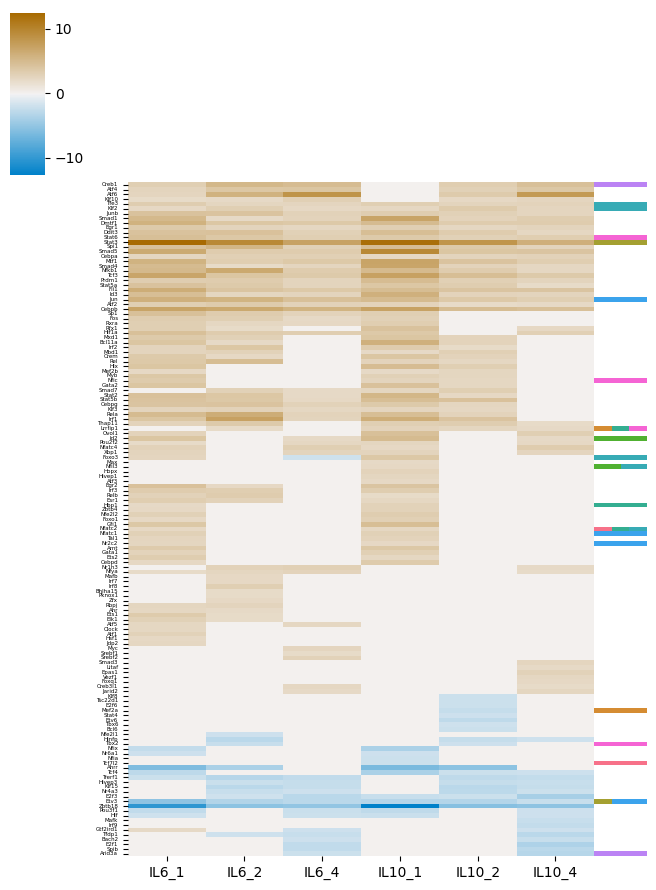

In [11]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("yellow_navy", ["#003366", "#ffffff", "#C9A800"])
cmap = sns.diverging_palette(240, 50, s=130, as_cmap=True)
act_heatmap = sns.clustermap(score_matrix_reordered, cmap=cmap, z_score=None,
                              row_cluster=False, col_cluster=False,
                              yticklabels=True, figsize=(7,9))
act_heatmap.ax_heatmap.yaxis.tick_left()
act_heatmap.ax_heatmap.set_yticklabels(
    act_heatmap.ax_heatmap.get_yticklabels(), fontsize=4
)

# --- Add split color column ---
reordered_tfs = list(score_matrix_reordered.index)  # top-to-bottom order
n_rows = len(reordered_tfs)

fig = act_heatmap.fig
ax_hm = act_heatmap.ax_heatmap
pos = ax_hm.get_position()  # figure coordinates

# Add new axis just to the right of the heatmap
ax_split = fig.add_axes([pos.x1, pos.y0, 0.075, pos.height])
ax_split.set_xlim(0, 1)
ax_split.set_ylim(0, n_rows)
ax_split.axis('off')

for i, tf in enumerate(reordered_tfs):
    colors = gene_to_colors.get(tf, None)
    row_y = n_rows - 1 - i
    if not colors:
        ax_split.add_patch(plt.Rectangle((0, row_y), 1, 1, color='white', ec='none'))
    else:
        n = len(colors)
        for j, color in enumerate(colors):
            ax_split.add_patch(plt.Rectangle((j/n, row_y), 1/n, 1, color=color, ec='none'))

act_heatmap.savefig(f'{out_dir}/figures/tf_scores.png', dpi=300, bbox_inches='tight')
act_heatmap.savefig(f'{out_dir}/figures/tf_scores.svg', dpi=300, bbox_inches='tight')
plt.show()